# Experimental: cross-section in height from pressure-level data, with orography

**This is an experimental example.** It reproduces the Metview gallery example [Cross Section in Height for Pressure Level Data with Orography](https://metview.readthedocs.io/en/latest/gen_files/gallery/cross_section_height_pl_orog.html) with earthkit-geo, [earthkit-meteo](https://earthkit-meteo.readthedocs.io), xarray and earthkit-plots. The temperature, which is given on pressure levels, is shown along a line in height above sea level, between 0 and 3000 m, and the orography is drawn as a black area. The horizontal part (the line and the regridding onto it) uses the new `earthkit.geo.polyline` module, whose interface may still change.

This is the simplified version of the [raw notebook](../raw/cross_section_height_pl_orog.ipynb). It uses the `cross_section()` and `pressure_to_height()` helpers from [../xsection.py](../xsection.py) instead of the hand-written regridding, geopotential-to-height conversion, vertical interpolation and Xarray steps.

The notebook reads a GRIB file. It contains forecast data of 2020-08-22 00 UTC.

To make this notebook work [earthkit-data](https://earthkit-data.readthedocs.io), [earthkit-meteo](https://earthkit-meteo.readthedocs.io), [earthkit-plots](https://earthkit-plots.readthedocs.io) and xarray have to be installed.

## Imports

In [1]:
import sys

import earthkit.data as ekd
import earthkit.plots as ekp
import numpy as np
from earthkit.geo.polyline import sample_polyline

sys.path.insert(0, "..")  # xsection.py is in docs/experimental
from xsection import cross_section, pressure_to_height

## Load the data

The file contains the temperature `t` and the geopotential `z` on the pressure levels 1000, 925, 850, 700, 400, 500 and 300 hPa (the order of the levels in the file is not monotonic: 400 comes before 500, the `cross_section()` helper sorts the levels), for the forecast step of 12 h, and the surface geopotential `z` from the analysis (step 0). It is a GRIB1 file on a regular 0.5° latitude-longitude grid over the area 40–51°N, 93–84°W. Here is a short listing of the first fields.

In [2]:
ds = ekd.from_source("sample", "xs_pl_orog.grib").to_fieldlist()
print(len(ds), "fields")
ds[:6].ls()

xs_pl_orog.grib:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

15 fields


,parameter.variable,time.valid_datetime,time.base_datetime,time.step,vertical.level,vertical.level_type,ensemble.member,geography.grid_type
0,t,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,1000,pressure,0,regular_ll
1,z,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,1000,pressure,0,regular_ll
2,t,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,925,pressure,0,regular_ll
3,z,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,925,pressure,0,regular_ll
4,t,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,850,pressure,0,regular_ll
5,z,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,850,pressure,0,regular_ll


## Select the temperature, the geopotential and the surface geopotential

We select `t` and `z` on the pressure levels, which gives 7 fields each, in one fieldlist, and `z` at the surface, which gives a single field, in another one. The geopotential is in m²/s². The surface geopotential is kept apart because it has a different forecast step than the other fields. The cell prints the pressure levels of the fields in the order they have in the file.

In [3]:
tz = ds.sel({"parameter.variable": ["t", "z"], "vertical.level_type": "pressure"})
zs = ds.sel({"parameter.variable": "z", "vertical.level_type": "surface"})

t_levels = [f.get("vertical.level") for f in tz.sel({"parameter.variable": "t"})]
print(len(tz), "fields in total on the pressure levels")
print(len(t_levels), "t fields, levels (hPa):", t_levels)
print(len(zs), "surface z field")

14 fields in total on the pressure levels
7 t fields, levels (hPa): [1000, 925, 850, 700, 400, 500, 300]
1 surface z field


## Define the line

[sample_polyline()](https://earthkit-geo.readthedocs.io) returns the latitudes and longitudes of 200 points along the line from (50.21°N, 91.82°W) to (40.82°N, 84.71°W), which is the line of the Metview example. We use `method="linear"`: the points are evenly spaced in latitude and longitude, i.e. they lie on a straight line in a plain latitude-longitude map, as in Metview. This is not the great circle, which is the default.

In [4]:
lats, lons = sample_polyline([50.21, 40.82], [-91.82, -84.71], n=200, method="linear")
print(lats.shape, (lats[0], lons[0]), (lats[-1], lons[-1]))

(200,) (np.float64(50.21), np.float64(-91.82)) (np.float64(40.82), np.float64(-84.71))


## Compute the cross-section on the line

The `cross_section()` helper from `../xsection.py` does the regridding and builds the Xarray Dataset in one call. The helper uses nearest-neighbour interpolation by default, so each point of the line gets the value of the nearest grid point. The levels are returned sorted by increasing pressure, from 300 to 1000 hPa. We call the helper twice: for the temperature and the geopotential on the pressure levels, which gives variables `t` and `z` on `level` (hPa) and `distance` (km, cumulative along the line), and for the surface geopotential, which has a different forecast step and cannot be converted together with the other fields. The latitudes and longitudes of the points are stored as auxiliary coordinates of `distance`.

During the regridding earthkit may log an `Error setting gridSpec` message with a traceback (a `GeocalculusError`), and MIR may print some `ECCODES` lines about the grid. Both are harmless: the regridding is not affected and the result is correct.

In [5]:
xs = cross_section(tz, lats, lons)  # t and z on the pressure levels
xs_zs = cross_section(zs, lats, lons)  # surface z, in a separate call
xs

Error setting gridSpec={"type": "unstructured_ll", "uid": "6d76a7b0bf55a727a549421e77eda507"}
ECCODES ERROR   :  grib_set_from_grid_spec: 'unstructured_grid' specified but input is GRIB edition 1.
ECCODES ERROR   :  GribFromSpec::set: Invalid argument


Problem with calculation of geographic attributes
Traceback (most recent call last):
  File "/Users/cgr/git/earthkit-data/src/earthkit/data/utils/message.py", line 299, in set
    return eccodes.codes_set(self._handle, name, value)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 2163, in grib_set
    grib_set_string(msgid, key, value)
    ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 523, in grib_set_string
    GRIB_CHECK(lib.grib_set_string(h, key.encode(ENC), bvalue, length_p))
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 232, in GRIB_CHECK
    errors.raise_grib_error(errid)
    ~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/errors.py", line 386, in raise_grib_error

Error setting gridSpec={"type": "unstructured_ll", "uid": "6d76a7b0bf55a727a549421e77eda507"}
ECCODES ERROR   :  grib_set_from_grid_spec: 'unstructured_grid' specified but input is GRIB edition 1.
ECCODES ERROR   :  GribFromSpec::set: Invalid argument


Problem with calculation of geographic attributes
Traceback (most recent call last):
  File "/Users/cgr/git/earthkit-data/src/earthkit/data/utils/message.py", line 299, in set
    return eccodes.codes_set(self._handle, name, value)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 2163, in grib_set
    grib_set_string(msgid, key, value)
    ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 523, in grib_set_string
    GRIB_CHECK(lib.grib_set_string(h, key.encode(ENC), bvalue, length_p))
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 232, in GRIB_CHECK
    errors.raise_grib_error(errid)
    ~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/errors.py", line 386, in raise_grib_error

<xarray.Dataset> Size: 27kB
Dimensions:                  (level: 7, distance: 200)
Coordinates:
  * level                    (level) int64 56B 300 400 500 700 850 925 1000
  * distance                 (distance) float64 2kB 0.0 5.831 ... 1.182e+03
    latitude                 (distance) float64 2kB 50.21 50.16 ... 40.87 40.82
    longitude                (distance) float64 2kB -91.82 -91.78 ... -84.71
    forecast_reference_time  datetime64[ns] 8B 2020-08-22
    step                     timedelta64[ns] 8B 12:00:00
    valid_time               datetime64[ns] 8B ...
Data variables:
    t                        (level, distance) float64 11kB 236.3 ... 297.4
    z                        (level, distance) float64 11kB 9.306e+04 ... 1.2...
Attributes:
    Conventions:  CF-1.8
    institution:  ECMWF

## Interpolate the temperature to height levels

The `pressure_to_height()` helper computes the geometric height of the pressure levels from the geopotential `z` and interpolates the temperature linearly in height from the pressure levels to the target heights 0, 20, 40, …, 3000 m above sea level, at each point of the line. The surface geopotential `xs_zs["z"]` is converted to the orography, which is added to the result. The temperature is still in K. The result is a Dataset with the temperature `t` on the dimensions `height` (m) and `distance` (km), and the orography on `distance` only. Heights below the lowest or above the highest level are missing (`NaN`).

In [6]:
target_h = np.arange(0, 3001, 20)  # m above sea level
xs_h = pressure_to_height(xs, target_h, zs=xs_zs["z"])
xs_h

<xarray.Dataset> Size: 249kB
Dimensions:                  (height: 151, distance: 200)
Coordinates:
  * height                   (height) int64 1kB 0 20 40 60 ... 2960 2980 3000
  * distance                 (distance) float64 2kB 0.0 5.831 ... 1.182e+03
    latitude                 (distance) float64 2kB 50.21 50.16 ... 40.87 40.82
    longitude                (distance) float64 2kB -91.82 -91.78 ... -84.71
    forecast_reference_time  datetime64[ns] 8B 2020-08-22
    step                     timedelta64[ns] 8B 12:00:00
    valid_time               datetime64[ns] 8B ...
Data variables:
    t                        (height, distance) float64 242kB nan nan ... 279.6
    orography                (distance) float64 2kB 372.8 372.8 ... 222.5 222.5
Attributes:
    Conventions:  CF-1.8
    institution:  ECMWF

## Convert the temperature to °C

The temperature is converted from K to °C by subtracting 273.15 (Metview uses 273.16, the difference of 0.01 °C is not visible), and its `units` attribute is updated.

In [7]:
# temperature: K -> degC
xs_h["t"] = xs_h["t"] - 273.15
xs_h["t"].attrs["units"] = "degC"
xs_h["t"]

<xarray.DataArray 't' (height: 151, distance: 200)> Size: 242kB
array([[       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       ...,
       [5.14609938, 5.14609938, 5.02028027, ..., 6.78168494, 6.71575143,
        6.71575143],
       [5.00905206, 5.00905206, 4.88295256, ..., 6.67133783, 6.60448931,
        6.60448931],
       [4.87200473, 4.87200473, 4.74562485, ..., 6.56099072, 6.49322719,
        6.49322719]], shape=(151, 200))
Coordinates:
  * height                   (height) int64 1kB 0 20 40 60 ... 2960 2980 3000
  * distance                 (distance) float64 2kB 0.0 5.831 ... 1.182e+03
    latitude                 (distance) float64 2kB 50.21 50.16 ... 40.87 40.82
    longitude                (distance) float64 2kB -91.82 -91.78 ... -84.71
    forecast_reference_time  datetime64[ns] 8B 2020-08-22
    step                     timedelta64[ns] 8B 12:00:00
    valid_time               datetime64[ns] 8B ...
Attributes:
    standard_name:  air_temperature
    long_name:      Temperature
    units:          degC

## Check the values above the ground

The interpolation does not use the orography, so the values below the ground are not set to missing by it. Below the ground they may be finite or `NaN`, depending on the heights of the levels, and in both cases they are hidden by the orography, which is drawn on top of the plot. What matters is that there are no missing values above the ground. The cell below counts the missing values below and above the ground (a target height above the ground is a height above the orography), and asserts that there are none above the ground.

In [8]:
above_ground = xs_h["height"] > xs_h["orography"]
nan = xs_h["t"].isnull()
print("NaNs below the ground:", int(nan.where(~above_ground, False).sum()), "of", int((~above_ground).sum()), "values")
print("NaNs above the ground:", int(nan.where(above_ground, False).sum()), "of", int(above_ground.sum()), "values")
assert not nan.where(above_ground, False).any(), "there must be no NaN above the ground"
t_above = xs_h["t"].where(above_ground)
print(f"temperature above the ground: {float(t_above.min()):.1f} to {float(t_above.max()):.1f} °C")

NaNs below the ground: 1104 of 3143 values
NaNs above the ground: 0 of 27057 values
temperature above the ground: 4.7 to 23.9 °C


## Plot the cross-section

We plot the filled contours of temperature with a non-map earthkit-plots `Subplot`, as in the Metview example, which has no map. The levels go from 4 to 25 °C every 1 °C. The colour map is the matplotlib `RdYlBu_r`, from blue through pale yellow to red. This is an approximate alternative to the Metview palette (pale blue, olive, yellow, orange and red), whose hues are noticeably different. Contour lines every 1 °C are drawn in charcoal, with a label every 2 °C. The colour bar is added with the `legend()` method of the figure. The orography is added with `fill_between()` and drawn in charcoal from the surface height down to 0 m, on top of the temperature. The vertical axis goes from 0 to 3000 m.

The 7 ticks of the horizontal axis are where the line crosses the whole longitudes 91°W, 90°W, …, 85°W, as in Metview. Their distance and latitude are found by linear interpolation along the sampled points, because they are not at sampled points. The labels have the latitude with up to 2 decimals (a trailing zero is dropped, as in Metview: "41.2°N/85°W") and the longitude in whole degrees.

Two details need explanation:

- `resample=False` is needed for `contourf()` and `contour()`. By default earthkit-plots resamples the data onto a 1000 × 1000 latitude-longitude grid, which is wrong for a distance-height section.
- The axis limits, the ticks and the labels are set with matplotlib calls on the axis `.ax` of the subplot, because earthkit-plots has no dedicated option for them.

['49.13°N/91°W', '47.81°N/90°W', '46.49°N/89°W', '45.17°N/88°W', '43.84°N/87°W', '42.52°N/86°W', '41.2°N/85°W']


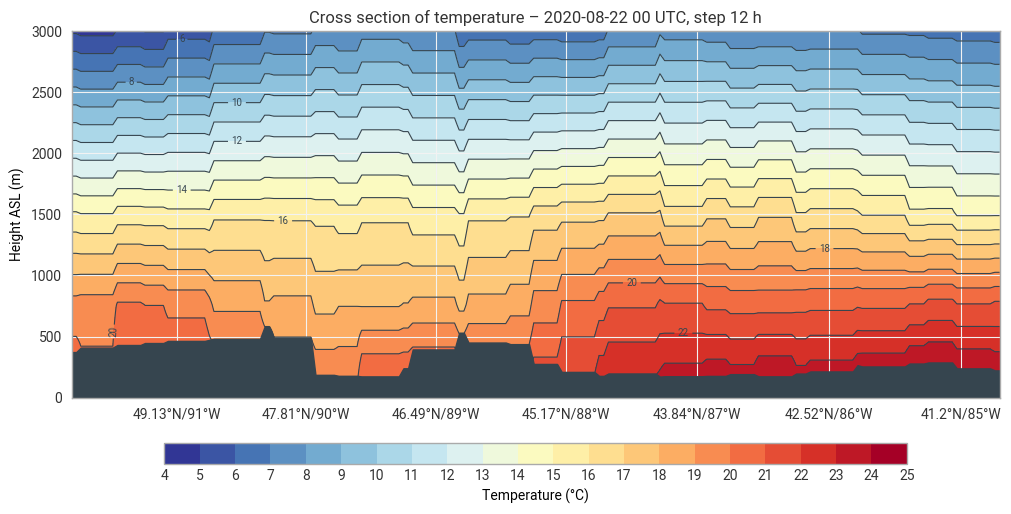

In [9]:
levels_t = list(range(4, 26))

# 7 ticks where the line crosses the longitudes 91W ... 85W (lons increase along the line)
distance = xs_h["distance"].values
tick_lons = np.arange(-91, -84)
tick_distance = np.interp(tick_lons, lons, distance)
tick_lats = np.interp(tick_lons, lons, lats)
tick_labels = [f"{round(lat, 2):g}°N/{abs(lon)}°W" for lat, lon in zip(tick_lats, tick_lons)]
print(tick_labels)

chart = ekp.Subplot(figsize=(10, 5))
chart.contourf(
    xs_h["t"],
    x="distance",
    y="height",
    style=ekp.styles.Style(levels=levels_t, colors="RdYlBu_r", ticks=levels_t),
    resample=False,
)
chart.contour(
    xs_h["t"],
    x="distance",
    y="height",
    style=ekp.styles.Contour(
        levels=levels_t,
        colors="#36454f",
        linewidths=0.8,
        labels=True,
        label_kwargs={"label_frequency": 2, "label_fmt": "%g"},
        legend_style=None,  # no second colour bar for the lines
    ),
    resample=False,
)
chart.figure.legend(label="Temperature (°C)")
# orography: charcoal polygon from the surface height down to 0 m, drawn on top
chart.fill_between(xs_h["orography"], 0, x=xs_h["distance"], color="#36454f", alpha=1)

ax = chart.ax
ax.set_xlim(distance[0], distance[-1])
ax.set_ylim(0, 3000)
ax.set_xticks(tick_distance)
ax.set_xticklabels(tick_labels)
ax.set_ylabel("Height ASL (m)")
ax.set_title("Cross section of temperature – 2020-08-22 00 UTC, step 12 h")

chart.show()